# Lab 04 · One configured NDVI job

Automated Workflows in Satellite Image Processing · Version 1.0 · 26 October 2026

In Lab 3 you acquired small red and NIR subsets and kept enough records to explain
where they came from. Today you turn those files into one repeatable processing
job. A later workflow manager will call this same job for many scenes.

The calculation is short. Most of the work is deciding what the calculation means,
checking its inputs, and keeping an honest account when execution fails.

You will write the database extension, repair three small functions, then run the
supplied CLI through success, reuse and recovery. Keep this notebook beside its
companion files. Start with README.md if you need to add packages.


In [18]:
from pathlib import Path
import json
import sqlite3
import subprocess
import sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "lab04_cli.py").is_file(), "Open this notebook from the extracted Lab 4 folder."

def cli(*arguments, expected=(0,)):
    result = subprocess.run([sys.executable, "lab04_cli.py", *map(str, arguments)], capture_output=True, text=True)
    if result.returncode not in expected:
        raise RuntimeError(f"Exit {result.returncode}: {result.stdout} {result.stderr}")
    return json.loads(result.stdout)

def check(part):
    result = subprocess.run([sys.executable, "check_lab04.py", "--part", part], capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    return result.returncode == 0

def query(config, sql, params=()):
    import yaml
    config = Path(config).resolve()
    settings = yaml.safe_load(config.read_text())
    database = (config.parent / settings["database"]).resolve()
    with sqlite3.connect(database.as_uri() + "?mode=ro", uri=True) as connection:
        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA foreign_keys=ON")
        return [dict(row) for row in connection.execute(sql, params)]

print("Python:", sys.version.split()[0], "Rasterio:", rasterio.__version__)

Python: 3.13.9 Rasterio: 1.4.4


## Exercise 1 · Write the processing schema

Write all six tables in student_processing_schema.sql using SCHEMA_CONTRACT.md.
You already designed the acquisition tables in Lab 3; support/ contains those
completed tables only. You are designing the processing extension here.

Start by explaining the difference between these records:

- A request to compute NDVI from two exact artifacts under specified settings.
- An attempt that could succeed, fail, stop unexpectedly or reuse a result.
- A file artifact whose bytes and interpretation are identified.
- A current location where those bytes might or might not still exist.

Lab 3 requires every artifacts row to reference an acquisition subset. NDVI is a
derived product. The processing registry links acquired inputs back to that table
and stores derived products without inventing acquisition records.

Decide which keys allow two retries of one request, while preventing two red
inputs in the same role. Decide which failures a foreign key can detect, and which
require checking files. Keep the existing discovery runs unchanged.

Run the check whenever you want feedback. Its failures are expected until your
schema is complete.

In [19]:
schema_ok = check("schema")

PASS schema



Explain one constraint that prevents bad lineage, and one condition that your
schema cannot establish by itself.
The constraint that prevents bad lineage is the foreign keys from processing_inputs and processing_outputs to processing_artifacts. An input or output cannot point to an artifact that does not exist. The composite primary key (request_id, role) also prevents two red inputs in one request, and the composite foreign key in processing_attempts guarantees that a reused attempt points to an attempt of the same request.

The schema cannot establish whether the file at local_path really exists with the correct size and SHA-256. The database stores text, and availability is checked by Python (verified_location). It also cannot enforce that a succeeded attempt has a row in processing_outputs, or that the input roles are exactly red and nir. The single publication transaction (publish) and the job code enforce those.


## Exercise 2 · What makes this the same request?

Repair make_request_spec in repair_functions.py. It currently uses dictionary
iteration order, omits important evidence and includes a storage path.

Return (normalized_spec, fingerprint). The normalized spec must be JSON compatible
and contain the stage, normalized scientific settings, ordered red/NIR input
records, environment and the policy name exact_environment_v1.

Keep all scientific settings, including a calibration review when present. Use
each input's artifact_id, sha256, size_bytes, raster and lineage; keep role names
explicit and in red, then nir order. Exclude registration times and runtime paths.
Normalize numeric parameters so 1 and 1.0 have the same interpretation. Produce
SHA-256 from JSON with sorted keys, compact separators and no NaN values.

This lab uses a conservative equivalence policy: a code or environment change
creates a new request. A later policy could permit equivalence across tested
environments, but that requires an explicit decision.

Predict the result of each change before running the check:

| Change | Same request or different request? | Why |
| --- | --- | --- |
| Write to a different disk | Same | `output_dir` and `log_dir` are excluded from the spec. Where the output is stored does not change the calculation. |
| Reorder YAML keys | Same | The spec is canonical JSON with sorted keys, and the roles have an explicit red, nir order. |
| Retry after a missing file is restored | Same | The bytes and checksum are identical, and file availability is not part of identity. It becomes a new attempt of the same request. |
| Change the AOI or input checksum | Different | Each input's `sha256`, `raster` and `lineage` (including `aoi_key`) enter the fingerprint. |
| Change the denominator threshold | Different | It is a scientific setting in `settings`. |
| Repair the algorithm implementation | Different | Under `exact_environment_v1` the code hash (`code_sha256`) is part of the environment, so a changed file changes the request. |
| Change the calibration interpretation | Different | The `scale`, `offset` and evidence values in `calibration` are in `settings`, not only the policy name. |

In [20]:
identity_ok = check("identity")

PASS identity



## Exercise 3 · A program can finish and still be wrong

Repair validate_pair and calculate_ndvi in repair_functions.py. These are logical
repairs: the supplied functions execute, but their assumptions are incomplete.

validate_pair must reject different scenes, collections, AOIs or extraction
recipes; incorrect band roles; and incompatible CRS, shape or pixel transforms.
Check that required radiometric metadata are finite and the scale is positive.
Equal shapes do not establish matching ground positions. This stage requires a
matching grid; resampling would need its own explicit preparation policy.

calculate_ndvi receives the stored DN arrays and the effective calibration chosen
in the request. Mask original nodata, convert before subtraction or addition, then
apply scale and offset separately for each band. Use
NDVI = (NIR reflectance - red reflectance) / (NIR reflectance + red reflectance).
Return float32, put NaN at invalid pixels and at denominators with absolute value
at most epsilon, and leave the inputs unchanged. Do not clip the saved values.

The calculation must support nonzero offsets. The demo's reviewed offset 0 is not
a reason to hard-code zero. The checks use the real arrays with their original
metadata as well as a deliberately high denominator threshold.

In [21]:
pair_ok = check("pair")
ndvi_ok = check("ndvi")

PASS pair

PASS ndvi



Explain these two bugs with a concrete example from the metadata or arrays:

1. Why can uint16 subtraction give the wrong sign?
2. Why does a shared multiplicative factor cancel in NDVI, while a shared additive
   offset generally does not?

   

    1 Sign with uint16. NumPy subtracts uint16 values with modulo 65536 arithmetic. At pixel [10, 196], red = 2876 and nir = 2580. The correct difference is −296, but in uint16 it comes out as 65240. The sign is lost, so a pixel whose NDVI should be negative comes out positive and large. That is why the arrays must be cast to float64 before any arithmetic. In the data, 141 of the 47,766 valid pixels have red > nir.

    2 Scale versus offset. A shared multiplicative factor cancels in the ratio: (s·N − s·R)/(s·N + s·R) = (N − R)/(N + R). I checked on the data that NDVI from raw DN and from offset-0 reflectance differ by at most about 10⁻¹⁶. A shared additive offset b does not cancel: (N − R)/(N + R + 2b) ≠ (N − R)/(N + R). For pixel [2, 64] (red = 365, nir = 4048), NDVI with offset −0.1 is 1.53, outside [−1, 1], while with offset 0 it is 0.83. The scene mean NDVI is 1.27 with −0.1 and 0.51 with 0. This is why CALIBRATION_REVIEW.md matters: the program runs correctly and the result is still scientifically wrong.

## Run one complete job

Finish the repairs before proceeding. The next cell runs a fresh Python process,
so it uses your current saved files rather than a notebook's cached module.

Use your own completed Lab 3 catalogue through the init/inputs/configure commands
in README.md, then change CONFIG below. Or leave the default to import the small
preserved real example. This explicit local route works without network access.
All following main-run cells use the CONFIG you choose.

In [22]:
assert check("all"), "Finish the schema and function repairs before creating processing evidence."

CONFIG = Path("demo/config/ndvi.yml")
if CONFIG == Path("demo/config/ndvi.yml") and not CONFIG.exists():
    print(cli("demo"))
assert CONFIG.is_file(), "Create your configuration using the README commands first."

import yaml
print(CONFIG.read_text())

PASS schema
PASS identity
PASS pair
PASS ndvi

database: C:\Users\mzawa\Desktop\mgr - II sem\Authomated_Workflows_Windows\Automated_Workflows\Labs\Lab04\demo\catalogue.sqlite
science:
  stage: ndvi_v1
  grid_policy: require_match
  scaling: reviewed_calibration
  mask_policy: nodata_only
  denominator_epsilon: 1.0e-06
  min_valid_fraction: 0.1
  calibration:
    red:
      sha256: df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441
      scale: 0.0001
      offset: 0.0
      evidence: 'Lab04 CALIBRATION_REVIEW.md: exact captured COG subsets; provider
        boa_offset_applied=true and DN distributions support offset 0. Teaching interpretation;
        no independent JP2 radiometric comparison.'
    nir:
      sha256: 94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72
      scale: 0.0001
      offset: 0.0
      evidence: 'Lab04 CALIBRATION_REVIEW.md: exact captured COG subsets; provider
        boa_offset_applied=true and DN distributions support offset 0. Te

Inspect the configuration before running. Which artifact fills each role? Where
will the output persist? What calibration does it request? What does nodata_only
say about clouds?

The plan command resolves identity and prints the normalized request without
registering a request or creating an attempt.

In [23]:
plan = cli("plan", "--config", CONFIG)
print("Planned request:", plan["request_id"])
print(json.dumps(plan["normalized_spec"]["settings"], indent=2))
first = cli("run", "--config", CONFIG)
print(json.dumps(first, indent=2))
assert first["request_id"] == plan["request_id"]

Planned request: request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403
{
  "calibration": {
    "nir": {
      "evidence": "Lab04 CALIBRATION_REVIEW.md: exact captured COG subsets; provider boa_offset_applied=true and DN distributions support offset 0. Teaching interpretation; no independent JP2 radiometric comparison.",
      "offset": 0.0,
      "scale": 0.0001,
      "sha256": "94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72"
    },
    "red": {
      "evidence": "Lab04 CALIBRATION_REVIEW.md: exact captured COG subsets; provider boa_offset_applied=true and DN distributions support offset 0. Teaching interpretation; no independent JP2 radiometric comparison.",
      "offset": 0.0,
      "scale": 0.0001,
      "sha256": "df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441"
    }
  },
  "denominator_epsilon": 1e-06,
  "grid_policy": "require_match",
  "mask_policy": "nodata_only",
  "min_valid_fraction": 0.1,
  "scaling": "reviewed_calib

Predict what the next invocation changes in the database. Then run it. If you
have already run the notebook, the first result above may itself be a reuse.

In [24]:
repeat = cli("run", "--config", CONFIG)
print(json.dumps(repeat, indent=2))
assert repeat["request_id"] == first["request_id"]
assert repeat["attempt_id"] != first["attempt_id"]
assert repeat["status"] == "reused"

{
  "status": "reused",
  "request_id": "request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403",
  "attempt_id": "attempt-774a5f5ed183426ba31ac2e94950f90d",
  "artifact_id": "output-c05f5356248f4a9be303e5a19d8e7b2022105b8d6b65b262b99b623404bc3610",
  "path": "C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\demo\\outputs\\attempt-e0a528ec7a5a4a7a9ab95aec5c0ebbce.ndvi.tif"
}


### Inspect the raster and its record

The display below uses a fixed NDVI color range. That only changes the display;
it does not clip the stored raster. Look at the reported coverage and range too.
No cloud classification data have been used.

Provenance tags: {'ATTEMPT_ID': 'attempt-e0a528ec7a5a4a7a9ab95aec5c0ebbce', 'CLOUD_SCREENED': 'false', 'MASK_POLICY': 'nodata_only', 'REQUEST_ID': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403', 'STAGE': 'ndvi_v1', 'AREA_OR_POINT': 'Area'}


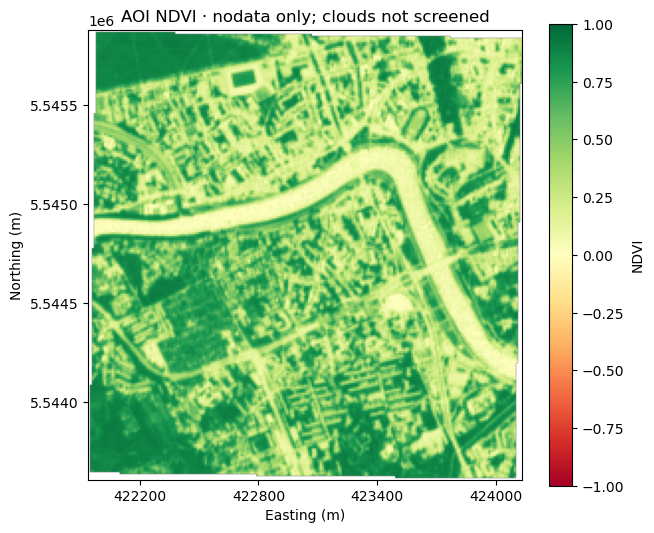

In [25]:
output_path = Path(repeat["path"])
from matplotlib.ticker import MaxNLocator
with rasterio.open(output_path) as source:
    ndvi = source.read(1, masked=True)
    bounds = source.bounds
    print("Provenance tags:", source.tags())
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1,
                      extent=(bounds.left, bounds.right, bounds.bottom, bounds.top))
    ax.set(title="AOI NDVI · nodata only; clouds not screened", xlabel="Easting (m)", ylabel="Northing (m)")
    ax.xaxis.set_major_locator(MaxNLocator(4))
    fig.colorbar(image, ax=ax, label="NDVI")
    plt.show()

In [26]:
history = query(CONFIG, """SELECT attempt_id,request_id,status,stage,started_at,finished_at,
    error_code,reused_from_attempt_id FROM processing_attempts ORDER BY started_at""")
history

[{'attempt_id': 'attempt-e0a528ec7a5a4a7a9ab95aec5c0ebbce',
  'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'succeeded',
  'stage': 'complete',
  'started_at': '2026-11-02T21:44:11.494323Z',
  'finished_at': '2026-11-02T21:44:11.679887Z',
  'error_code': None,
  'reused_from_attempt_id': None},
 {'attempt_id': 'attempt-ba5ae8310470484eae0fd03455f39601',
  'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'reused',
  'stage': 'complete',
  'started_at': '2026-11-02T21:44:12.244489Z',
  'finished_at': '2026-11-02T21:44:12.331570Z',
  'error_code': None,
  'reused_from_attempt_id': 'attempt-e0a528ec7a5a4a7a9ab95aec5c0ebbce'},
 {'attempt_id': 'attempt-4fa975850fd84b5cacf1948b4edd2a53',
  'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'reused',
  'stage': 'complete',
  'started_at': '2026-11-02T22:11:45.081393Z',
  'finished_at': 

Write a query in investigation_queries.sql that starts with the NDVI artifact
and traces it to its successful producing attempt, request, input roles and the
original Lab 3 scene/asset/AOI records. Run your query below. The output-to-input
links are the explanation; filenames are only convenient locations.

Replace the harmless starter query with your lineage query.

In [27]:
query(CONFIG, "SELECT artifact_id, sha256, size_bytes FROM processing_artifacts")

[{'artifact_id': 'input-59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1',
  'sha256': 'df429fb5eff330afe76e6dd0b7e749fba163e77dada3bdf6c6e18e430c601441',
  'size_bytes': 75792},
 {'artifact_id': 'input-fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb',
  'sha256': '94733ceb5a90b44961485d021290543635df521a4c1da4d6fbb79ef7ec5f7d72',
  'size_bytes': 76138},
 {'artifact_id': 'output-c05f5356248f4a9be303e5a19d8e7b2022105b8d6b65b262b99b623404bc3610',
  'sha256': '58ab906539adc732893ba3b714eff2873a9ecba393138aec084ef6d424abee93',
  'size_bytes': 160641}]

What is the difference between producing an artifact and returning it from a
reused attempt? Where is the calibration review preserved?

Producing an artifact means a succeeded attempt: it computed the raster, wrote the file, and in one transaction added the artifact, the location and the row in processing_outputs. A reused attempt computes nothing. It finds an earlier succeeded attempt of the same request, verifies the file (hash and validation), and points to the same artifact through processing_outputs, recording reused_from_attempt_id. To find the actual producer, follow the output link to the attempt with status succeeded.

The calibration review is preserved in processing_requests.normalized_json (settings.calibration with scale, offset, hash and evidence), in the attempt’s original_config and resolved_config_json, and in the inputs’ raster_json (the original −0.1 header offset stays untouched).

## Exercise 4 · Diagnose before retrying

These cases use separate copies of the same real example under cases/. They leave
your main archive alone and refuse to overwrite an existing case. The helper below
lets you inspect a case again when you rerun this notebook.

### Case A · A recorded input has disappeared

Predict the new attempt's status and the location status. The case moves its own
red file aside, then calls the normal job. It does not change the request settings.
The deliberate failure exit code is 1.

In [28]:
def ensure_case(name):
    config = Path("cases") / name / "config/ndvi.yml"
    if not config.exists():
        result = cli("case", "--name", name, expected=(1, 86))
        print("Created case:", name, "child exit:", result["exit_code"])
    return config

missing_config = ensure_case("missing-input")
query(missing_config, "SELECT attempt_id,request_id,status,stage,error_code,error_message FROM processing_attempts")

[{'attempt_id': 'attempt-dcba701598634601bd85ef715f0011a5',
  'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'failed',
  'stage': 'validate_inputs',
  'error_code': 'FileNotFoundError',
  'error_message': 'No verified location for input-59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1; inspect processing_artifact_locations'},
 {'attempt_id': 'attempt-b916b5d7ef174f26bfa109226b17d561',
  'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'succeeded',
  'stage': 'complete',
  'error_code': None,
  'error_message': None}]

In [29]:
query(missing_config, "SELECT artifact_id,local_path,status,checked_at FROM processing_artifact_locations")

[{'artifact_id': 'input-59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1',
  'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\cases\\missing-input\\inputs\\red.tif',
  'status': 'available',
  'checked_at': '2026-11-02T21:45:06.050292Z'},
 {'artifact_id': 'input-fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb',
  'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\cases\\missing-input\\inputs\\nir.tif',
  'status': 'available',
  'checked_at': '2026-11-02T21:45:06.067268Z'},
 {'artifact_id': 'output-3bf42b899ff760af412289ea3505213d77a3d52c74bd075ec399f19f2c3bb96e',
  'local_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\cases\\missing-input\\outputs\\attempt-b916b5d7ef174f26bfa109226b17d561.ndvi.tif',
  'status': 'available',
  'checked_at': '2026-11-0

Add diagnostic SQL to investigation_queries.sql. Identify the exact input role
that failed and explain why the old input artifact still exists in the database.
Predict whether restoring the identical file creates a new scientific request.

Prediction: a new attempt with status failed, and the location of the red file changes to missing.

Diagnosis: the attempt ends as failed at stage validate_inputs with error code FileNotFoundError. The message contains the artifact ID, which I map to the red role through processing_inputs. verified_location checks the inputs in order, so red is checked first and is the one that fails. The old artifact still exists because the registry is immutable: an artifact describes bytes, not their presence. Only the location row changes. Query: SELECT ... FROM processing_inputs i JOIN processing_artifacts a USING(artifact_id) JOIN processing_artifact_locations l USING(artifact_id) WHERE l.status <> 'available'.

Does restoring the file create a new request? No. The file has the same hash, and the configuration and code are unchanged, so the fingerprint is the same. It is a new attempt of the same request, and the failed attempt stays in the history.

After recording your diagnosis, restore the case input and retry. Do not delete
the failed attempt.

In [30]:
case_root = missing_config.parent.parent
note = json.loads((case_root / "case_note.json").read_text())
if Path(note["held"]).exists() and not Path(note["original"]).exists():
    print(cli("restore-input", "--config", missing_config))
recovered_missing = cli("run", "--config", missing_config)
print(json.dumps(recovered_missing, indent=2))
query(missing_config, "SELECT request_id,status,error_code FROM processing_attempts ORDER BY started_at")

{
  "status": "reused",
  "request_id": "request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403",
  "attempt_id": "attempt-ad79338f547f4030bdc75c62392fe9a0",
  "artifact_id": "output-3bf42b899ff760af412289ea3505213d77a3d52c74bd075ec399f19f2c3bb96e",
  "path": "C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\cases\\missing-input\\outputs\\attempt-b916b5d7ef174f26bfa109226b17d561.ndvi.tif"
}


[{'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'failed',
  'error_code': 'FileNotFoundError'},
 {'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'succeeded',
  'error_code': None},
 {'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'status': 'reused',
  'error_code': None}]

### Case B · The process stops before publication

The case writes and validates a real temporary NDVI file, commits a receipt, then
the child process immediately exits with code 86. It cannot run an exception
handler. The parent command waits for that child to stop.

Before running it, predict: which status will the database show, which file will
exist, and will a processing_outputs row exist?

In [31]:
stopped_config = ensure_case("before-rename")
stopped_rows = query(stopped_config, "SELECT attempt_id,request_id,status,stage,temp_path,final_path,receipt_json FROM processing_attempts ORDER BY started_at")
for row in stopped_rows:
    print({key: row[key] for key in ("attempt_id", "status", "stage")},
          "temp exists:", Path(row["temp_path"]).exists(), "final exists:", Path(row["final_path"]).exists())
print("Output links:", query(stopped_config, "SELECT * FROM processing_outputs"))

{'attempt_id': 'attempt-c8b737855c3b4cef8f9f1f007f1a8d89', 'status': 'interrupted', 'stage': 'before_rename'} temp exists: False final exists: False
{'attempt_id': 'attempt-91a2415e22764fefa45374d0d0c93e61', 'status': 'succeeded', 'stage': 'complete'} temp exists: False final exists: True
Output links: [{'attempt_id': 'attempt-91a2415e22764fefa45374d0d0c93e61', 'role': 'ndvi', 'artifact_id': 'output-05be11a8ba5a656d1364fe00c0b6287ab5d18eb3300891587fc312158e07ee13'}]


A running row does not prove a process is still running. A missing error does
not prove success. Write down the evidence establishing that this child stopped.
Explain why retrying an unresolved running attempt is blocked in this lab.



In [32]:
running = [row for row in stopped_rows if row["status"] == "running"]
for row in running:
    print(cli("reconcile", "--config", stopped_config, "--attempt-id", row["attempt_id"], "--confirm-stopped"))
recovered_stop = cli("run", "--config", stopped_config)
print(json.dumps(recovered_stop, indent=2))
query(stopped_config, "SELECT request_id,attempt_id,status,stage,error_code FROM processing_attempts ORDER BY started_at")

{
  "status": "reused",
  "request_id": "request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403",
  "attempt_id": "attempt-6c9b7a83a80c49a0ae1b02210723a9e8",
  "artifact_id": "output-05be11a8ba5a656d1364fe00c0b6287ab5d18eb3300891587fc312158e07ee13",
  "path": "C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab04\\cases\\before-rename\\outputs\\attempt-91a2415e22764fefa45374d0d0c93e61.ndvi.tif"
}


[{'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'attempt_id': 'attempt-c8b737855c3b4cef8f9f1f007f1a8d89',
  'status': 'interrupted',
  'stage': 'before_rename',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH'},
 {'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'attempt_id': 'attempt-91a2415e22764fefa45374d0d0c93e61',
  'status': 'succeeded',
  'stage': 'complete',
  'error_code': None},
 {'request_id': 'request-277d49627a2742e29ea94a0427dabd4a3bcea3027bdfe1dc7eec7cc767e36403',
  'attempt_id': 'attempt-6c9b7a83a80c49a0ae1b02210723a9e8',
  'status': 'reused',
  'stage': 'complete',
  'error_code': None}]

Why is this a new attempt of the same request? What happened to the temporary
file? Which SQL rows show that recovery did not erase the interruption?

Prediction before running: status running, the temporary .partial.tif file exists, there is no final file, and there is no row in processing_outputs.

Evidence the process stopped: the case command runs the child with subprocess.run, which waits for it to finish. The child ends with exit code 86 through os._exit, without running any exception handler. A running row alone proves nothing, because a process cannot report its own death, and a missing error does not mean success.

Why retrying is blocked: new_attempt refuses when any attempt is running. A live process could still rename the file and publish its result, so two processes could write the same output and the registry would become inconsistent.

Why a new attempt of the same request: a request describes the calculation, not the execution. Nothing about it has changed, so a new attempt with a new attempt_id is created.

The temporary file: after reconcile it was moved to quarantine/, not deleted. SQL rows showing the interruption was not erased: the old attempt has status interrupted, error code PROCESS_STOPPED_BEFORE_PUBLISH, a finished_at value, its receipt_json still stored and stage before_rename, and there is no row in processing_outputs for it. Next to it is the new succeeded attempt.

## Optional · The file was renamed, but the database transaction never happened

Generate `python lab04_cli.py case --name after-rename`, inspect its paths,
receipt and absent output link, then reconcile it using the exact attempt ID.
The same reconciliation command validates the final file and adopts it. Explain
why recomputing is unnecessary and why file existence alone would be insufficient.

The rename and database commit are separate operations. A transaction in SQLite
does not make a filesystem rename part of that transaction.

Further investigation: move an output aside, run the main job again and explain
why the historical succeeded row remains while availability changes. Use a copy
of your workspace and retain the file so you can restore it.

*Write your evidence here if you complete an extension.*

## Evidence to hand in

Submit student_processing_schema.sql, repair_functions.py, this completed
notebook, investigation_queries.sql and small JSON reports for the main job and
both required cases. Keep actual data, rasters, databases and logs locally for
demonstration, rather than adding them to Git.

The next cell saves reports. It does not recreate an image or recompute NDVI.

In [17]:
for label, config in (("main", CONFIG), ("missing_input", missing_config), ("interrupted", stopped_config)):
    destination = Path("evidence") / (label + "_report.json")
    cli("report", "--config", config, "--out", destination)
    print(destination)

evidence\main_report.json
evidence\missing_input_report.json
evidence\interrupted_report.json


Finish with a short explanation of what a future coordinator needs from this
job: how to specify the intended calculation, recognize a usable result and decide
whether to retry. Which part still needs a human scientific judgment?

A future coordinator needs three things from this job:

How to specify the calculation: an unambiguous fingerprint (request_id) built from the inputs (checksums and lineage), scientific settings, calibration and environment, without paths.
How to recognize a usable result: a succeeded or reused row with an output in processing_outputs, and above all a check of the file itself (size, SHA-256, grid, tags, valid pixel fraction).
When to retry: failed can be retried once the cause is removed, and running only after establishing that the process is dead and reconciling it.

Human scientific judgment is still needed for whether the calibration is correct (the −0.1 versus 0 offset conflict is an example), whether the data suit the purpose (there is no cloud mask), and whether values outside [−1, 1] are acceptable.

Your final evidence should show one complete NDVI lineage, a reuse invocation,
a preserved missing-input failure followed by recovery, and a stopped attempt
followed by reconciliation and a successful retry. Restart the kernel and run the
notebook again after saving your repairs; the notebook inspects existing case
workspaces and appends valid main invocations without overwriting the evidence.